# Drug–Target Interaction Prediction

## Notebook 04: Exploratory Data Analysis

### Objective

This notebook explores the integrated drug–target dataset before
machine-learning model development.

The analysis focuses on three major components:

1. Drug molecular properties
2. Protein sequence-derived properties
3. Experimentally measured binding affinity

### Biological Questions

- How are the selected protein targets represented in the dataset?
- How is binding affinity distributed across drug–target pairs?
- What are the chemical characteristics of the compounds?
- How do the selected proteins differ in sequence composition?
- Are molecular or protein features associated with binding affinity?

### Dataset

The integrated dataset contains:

- 18,745 drug–protein observations
- 11 human protein targets
- Molecular descriptors generated using RDKit
- Protein sequence features
- Experimentally measured pChEMBL values

## 1. Import Libraries

The required libraries are imported for numerical analysis,
visualization, and statistical exploration.

In [45]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

print("RDKit imported successfully.")

RDKit imported successfully.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load Integrated ML Dataset

The integrated dataset generated in Notebook 03 is loaded for
exploratory analysis.

The dataset contains molecular, protein, and binding-affinity
information for each drug–protein pair.

In [2]:
ml_df = pd.read_csv(
    "../data/processed/ml_feature_dataset.csv"
)

print("Dataset loaded successfully.")
print("Rows:", ml_df.shape[0])
print("Columns:", ml_df.shape[1])

Dataset loaded successfully.
Rows: 18745
Columns: 42


## 3. Dataset Overview

We inspect the dimensions, variables, data types, and summary statistics
of the integrated dataset before performing detailed analysis.

In [3]:
ml_df.head()

,molecule_chembl_id,target_chembl_id,pchembl_value,n_measurements,activity_types,pref_name_x,organism,canonical_smiles,mol_weight,logp,...,Q_freq,R_freq,S_freq,T_freq,V_freq,W_freq,Y_freq,hydrophobic_fraction,charged_fraction,aromatic_fraction
0,CHEMBL10,CHEMBL1862,5.495,2,Kd,Tyrosine-protein kinase ABL1,Homo sapiens,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,377.444,4.6822,...,0.029204,0.056637,0.106195,0.057522,0.054867,0.011504,0.026549,0.334513,0.246018,0.063717
1,CHEMBL10,CHEMBL203,5.770,23,Kd,Epidermal growth factor receptor,Homo sapiens,C[S+]([O-])c1ccc(-c2nc(-c3ccc(F)cc3)c(-c3ccncc...,377.444,4.6822,...,0.040496,0.049587,0.069421,0.052893,0.057851,0.010744,0.029752,0.357025,0.218182,0.070248
2,CHEMBL1000,CHEMBL231,7.500,11,Ki,Histamine H1 receptor,Homo sapiens,O=C(O)COCCN1CCN(C(c2ccccc2)c2ccc(Cl)cc2)CC1,388.895,3.1482,...,0.032854,0.055441,0.088296,0.055441,0.063655,0.022587,0.036961,0.431211,0.207392,0.108830
3,CHEMBL100075,CHEMBL205,8.150,1,Ki,Carbonic anhydrase 2,Homo sapiens,CC(C)c1cc(-c2ccccc2)cc(C(C)C)[n+]1CC(=O)OCCOc1...,654.163,0.0112,...,0.042308,0.026923,0.069231,0.046154,0.065385,0.026923,0.030769,0.361538,0.242308,0.103846
4,CHEMBL100109,CHEMBL204,9.620,1,Ki,Prothrombin,Homo sapiens,CC(=O)N[C@H](Cc1ccccc1)C(=O)N1CCC[C@H]1C(=O)N[...,432.330,-0.6494,...,0.041801,0.070740,0.061093,0.057878,0.059486,0.022508,0.033762,0.348875,0.255627,0.090032


In [4]:
ml_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18745 entries, 0 to 18744
Data columns (total 42 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   molecule_chembl_id    18745 non-null  object 
 1   target_chembl_id      18745 non-null  object 
 2   pchembl_value         18745 non-null  float64
 3   n_measurements        18745 non-null  int64  
 4   activity_types        18745 non-null  object 
 5   pref_name_x           18745 non-null  object 
 6   organism              18745 non-null  object 
 7   canonical_smiles      18745 non-null  object 
 8   mol_weight            18745 non-null  float64
 9   logp                  18745 non-null  float64
 10  tpsa                  18745 non-null  float64
 11  hbd                   18745 non-null  float64
 12  hba                   18745 non-null  float64
 13  rotatable_bonds       18745 non-null  float64
 14  ring_count            18745 non-null  float64
 15  fraction_csp3      

In [5]:
ml_df.describe()

,pchembl_value,n_measurements,mol_weight,logp,tpsa,hbd,hba,rotatable_bonds,ring_count,fraction_csp3,...,Q_freq,R_freq,S_freq,T_freq,V_freq,W_freq,Y_freq,hydrophobic_fraction,charged_fraction,aromatic_fraction
count,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,...,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000,18745.000000
mean,7.108222,1.494105,463.980311,2.773600,120.497624,2.687703,5.843905,6.692131,3.588637,0.278112,...,0.041710,0.043814,0.074168,0.053387,0.061334,0.021804,0.032342,0.360911,0.235629,0.094411
std,1.339604,4.832157,266.115204,2.468471,116.719148,3.169068,5.497319,6.458369,2.166646,0.191695,...,0.005513,0.017579,0.014231,0.009760,0.005683,0.006183,0.003125,0.026064,0.019683,0.013719
min,1.050000,1.000000,27.026000,-36.105700,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.029204,0.026923,0.047923,0.037433,0.042017,0.008403,0.026549,0.291358,0.188088,0.063717
25%,6.180000,1.000000,359.418000,1.470000,80.990000,1.000000,4.000000,4.000000,3.000000,0.133333,...,0.041801,0.026923,0.069136,0.046154,0.059486,0.017241,0.030769,0.348875,0.218182,0.090032
50%,7.170000,1.000000,436.520000,2.914000,108.510000,2.000000,5.000000,6.000000,4.000000,0.260870,...,0.042308,0.040752,0.069231,0.052893,0.063655,0.022587,0.030769,0.361538,0.242308,0.103846
75%,8.090000,1.000000,528.723000,4.350200,142.110000,3.000000,7.000000,8.000000,4.000000,0.388889,...,0.042308,0.056637,0.075630,0.057878,0.065385,0.026923,0.033762,0.361538,0.246018,0.103846
max,11.000000,528.000000,10188.534000,16.766220,4638.220000,98.000000,247.000000,179.000000,85.000000,1.000000,...,0.054054,0.073482,0.109395,0.078370,0.074866,0.026923,0.038655,0.431211,0.267380,0.108830


## 4. Data Completeness Check

Before performing EDA, we verify that the integrated dataset contains
complete observations without missing feature values.

In [6]:
missing_values = (
    ml_df.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_values[missing_values > 0]

Series([], dtype: int64)

In [7]:
print("Duplicate rows:", ml_df.duplicated().sum())

Duplicate rows: 0


## 5. Distribution of Drug–Protein Interactions

The number of drug–protein observations varies across the selected
protein targets.

Understanding this distribution is important because highly represented
targets may have greater influence during model training.

In [8]:
target_counts = (
    ml_df["target_chembl_id"]
    .value_counts()
)

target_counts

target_chembl_id
CHEMBL205     8172
CHEMBL204     3600
CHEMBL231     1456
CHEMBL2000    1081
CHEMBL1862    1049
CHEMBL2034    1030
CHEMBL1801     619
CHEMBL203      597
CHEMBL206      578
CHEMBL202      340
CHEMBL1952     223
Name: count, dtype: int64

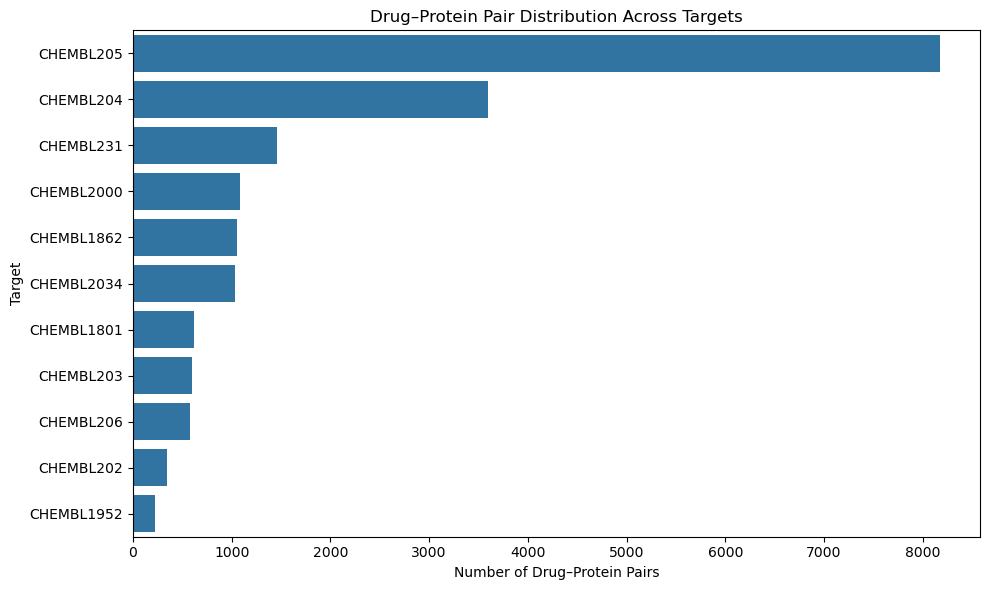

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_counts.values,
    y=target_counts.index
)

plt.xlabel("Number of Drug–Protein Pairs")
plt.ylabel("Target")
plt.title("Drug–Protein Pair Distribution Across Targets")

plt.tight_layout()
plt.show()

In [14]:
target_names = (
    ml_df[
        ["target_chembl_id", "pref_name_x"]
    ]
    .drop_duplicates()
    .set_index("target_chembl_id")["pref_name_x"]
)

target_counts_named = target_counts.rename(index=target_names)

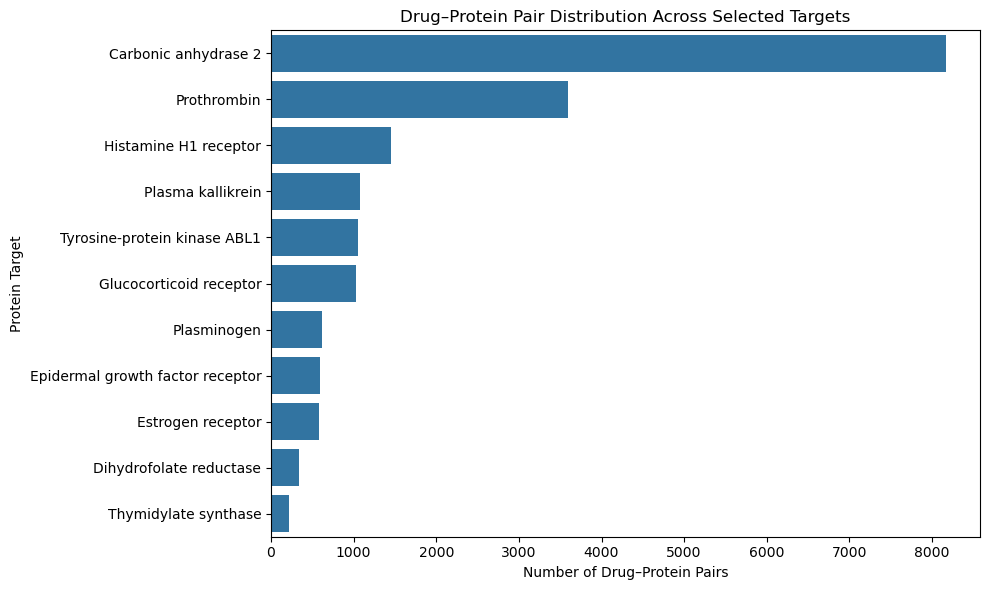

In [15]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_counts_named.values,
    y=target_counts_named.index
)

plt.xlabel("Number of Drug–Protein Pairs")
plt.ylabel("Protein Target")
plt.title("Drug–Protein Pair Distribution Across Selected Targets")

plt.tight_layout()
plt.show()

## 6. Binding-Affinity Distribution

pChEMBL is the primary response variable used in this project.

Higher pChEMBL values generally indicate stronger measured binding
affinity.

We examine its overall distribution to understand the range and
variability of experimentally observed binding affinities.

In [16]:
ml_df["pchembl_value"].describe()

count    18745.000000
mean         7.108222
std          1.339604
min          1.050000
25%          6.180000
50%          7.170000
75%          8.090000
max         11.000000
Name: pchembl_value, dtype: float64

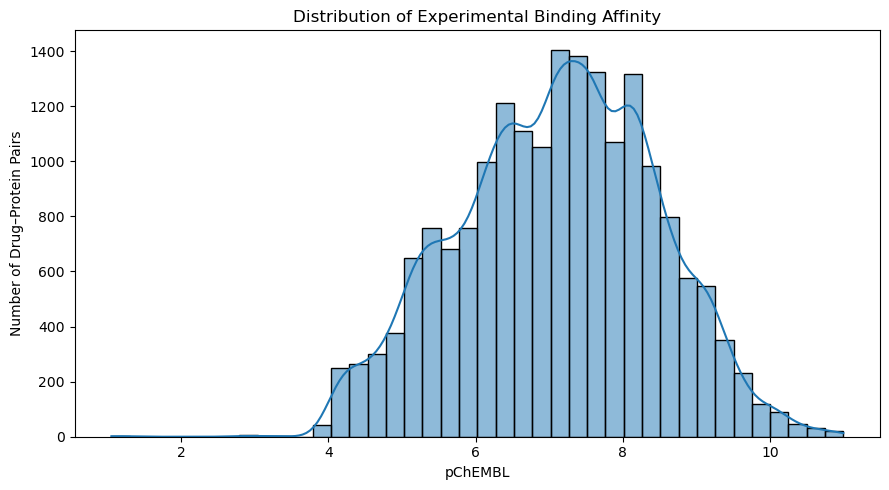

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    ml_df["pchembl_value"],
    bins=40,
    kde=True
)

plt.xlabel("pChEMBL")
plt.ylabel("Number of Drug–Protein Pairs")
plt.title("Distribution of Experimental Binding Affinity")

plt.tight_layout()
plt.show()

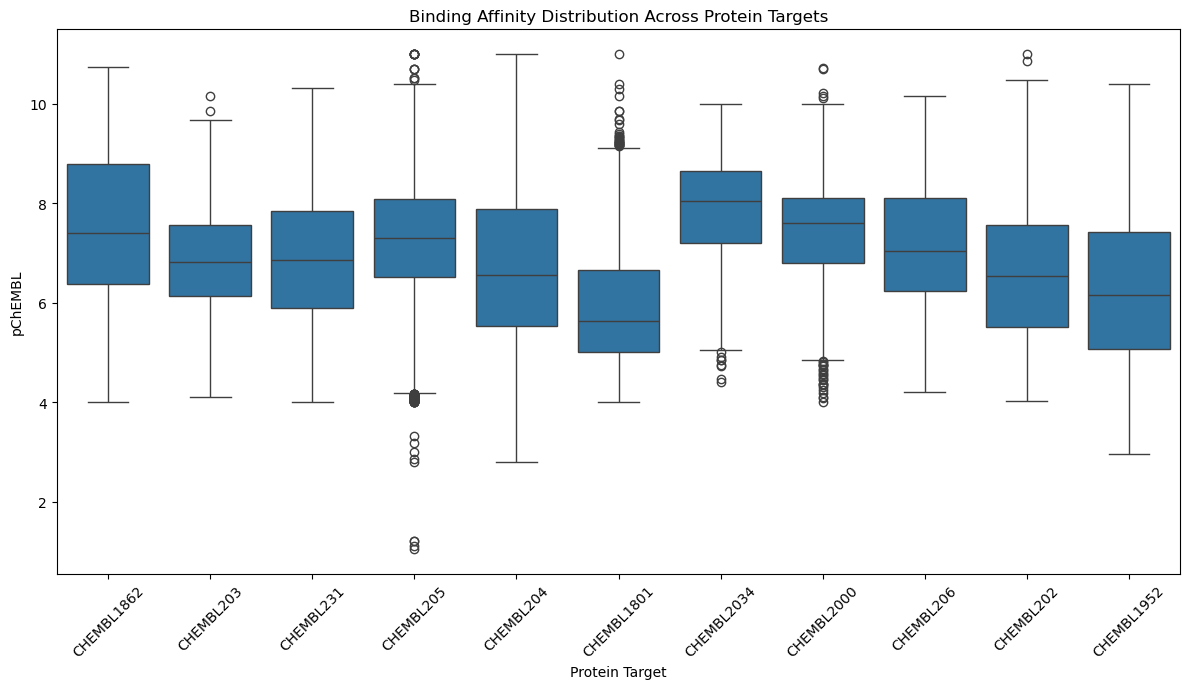

In [18]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=ml_df,
    x="target_chembl_id",
    y="pchembl_value"
)

plt.xlabel("Protein Target")
plt.ylabel("pChEMBL")
plt.title("Binding Affinity Distribution Across Protein Targets")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [19]:
plot_df = ml_df.copy()

plot_df["target_name"] = (
    plot_df["target_chembl_id"]
    .map(target_names)
)

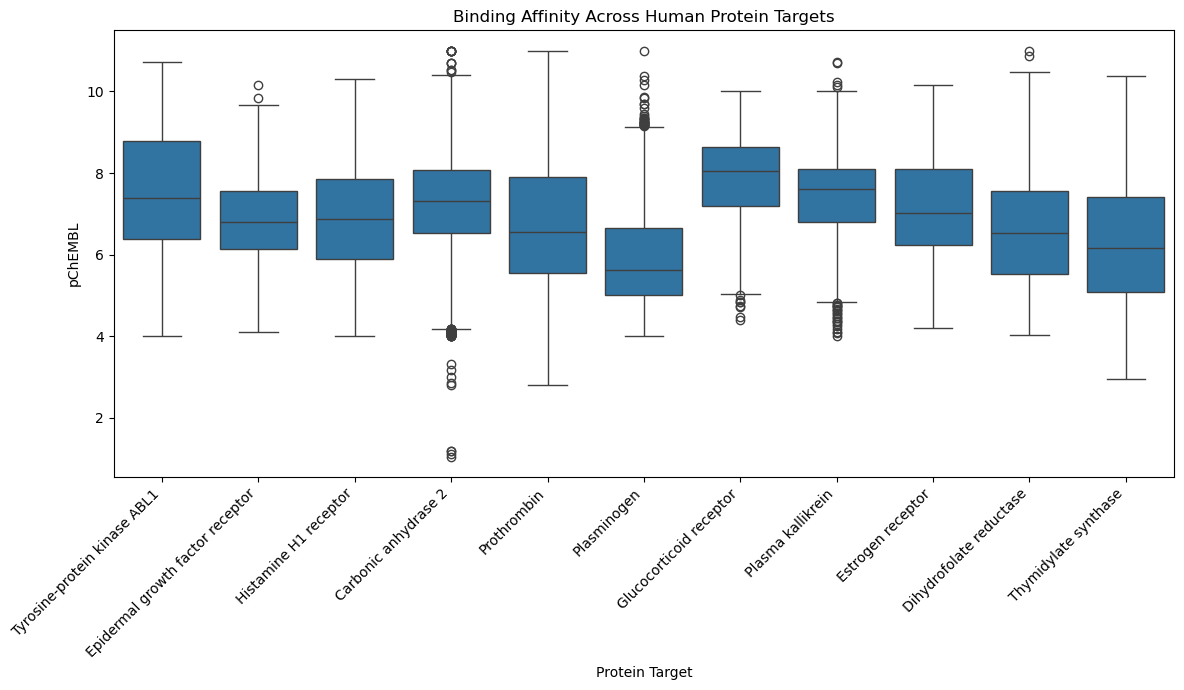

In [20]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=plot_df,
    x="target_name",
    y="pchembl_value"
)

plt.xlabel("Protein Target")
plt.ylabel("pChEMBL")
plt.title("Binding Affinity Across Human Protein Targets")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

## 8. Molecular Weight Distribution

Molecular weight provides a basic measure of compound size.

The distribution is examined to understand the chemical space represented
by the compounds in the dataset.

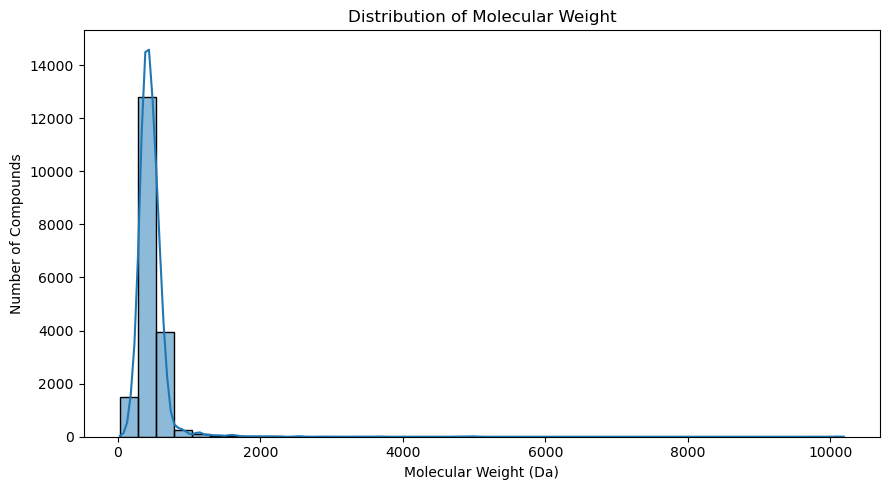

In [22]:
plt.figure(figsize=(9, 5))

sns.histplot(
    ml_df["mol_weight"],
    bins=40,
    kde=True
)

plt.xlabel("Molecular Weight (Da)")
plt.ylabel("Number of Compounds")
plt.title("Distribution of Molecular Weight")

plt.tight_layout()
plt.show()

## 9. LogP Distribution

LogP describes the relative preference of a compound for a
hydrophobic versus aqueous environment.

It is commonly used as an indicator of molecular lipophilicity and can
influence molecular interactions, permeability, and solubility.

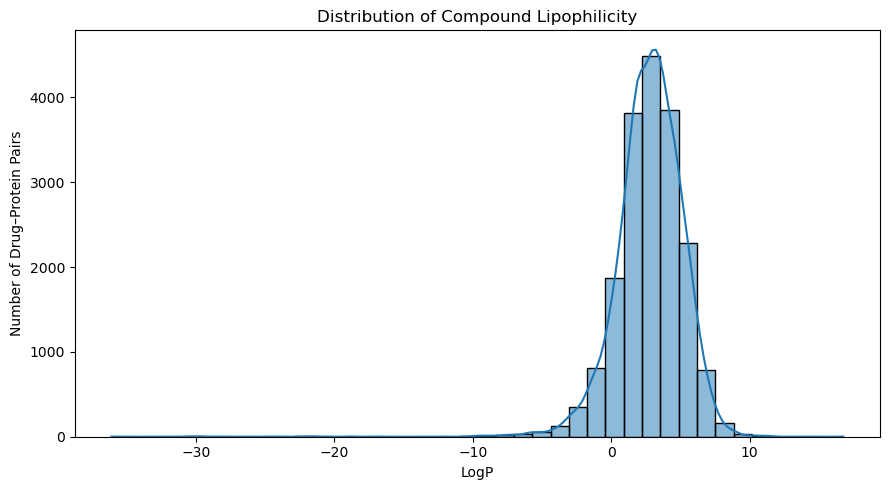

In [23]:
plt.figure(figsize=(9, 5))

sns.histplot(
    ml_df["logp"],
    bins=40,
    kde=True
)

plt.xlabel("LogP")
plt.ylabel("Number of Drug–Protein Pairs")
plt.title("Distribution of Compound Lipophilicity")

plt.tight_layout()
plt.show()

## 10. Topological Polar Surface Area

Topological polar surface area (TPSA) provides an estimate of the
polar surface of a molecule.

It is related to hydrogen bonding and other physicochemical properties
that can influence molecular recognition and pharmacokinetic behavior.

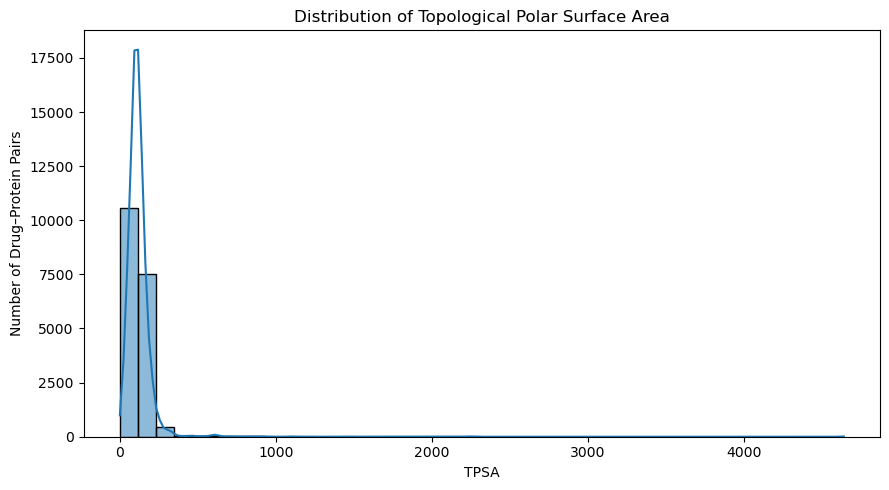

In [24]:
plt.figure(figsize=(9, 5))

sns.histplot(
    ml_df["tpsa"],
    bins=40,
    kde=True
)

plt.xlabel("TPSA")
plt.ylabel("Number of Drug–Protein Pairs")
plt.title("Distribution of Topological Polar Surface Area")

plt.tight_layout()
plt.show()

## 11. Correlation Among Molecular Properties

Correlation analysis is used to examine relationships between molecular
descriptors.

Highly correlated features may provide overlapping information and
can be considered during later model development.

In [25]:
drug_feature_columns = [
    "mol_weight",
    "logp",
    "tpsa",
    "hbd",
    "hba",
    "rotatable_bonds",
    "ring_count",
    "fraction_csp3"
]

drug_corr = ml_df[
    drug_feature_columns
].corr()

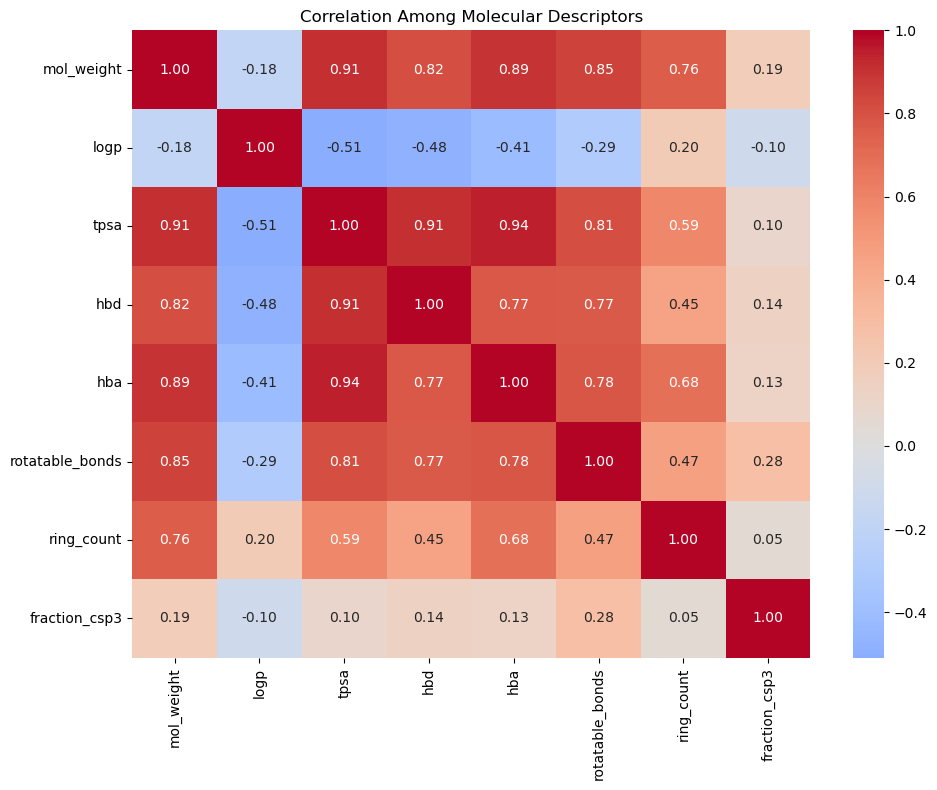

In [26]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    drug_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Among Molecular Descriptors")

plt.tight_layout()
plt.show()

## 12. Molecular Weight vs Binding Affinity

The relationship between molecular weight and experimentally measured
binding affinity is examined using a scatter plot.

This is exploratory and does not imply that molecular weight alone
determines binding affinity.

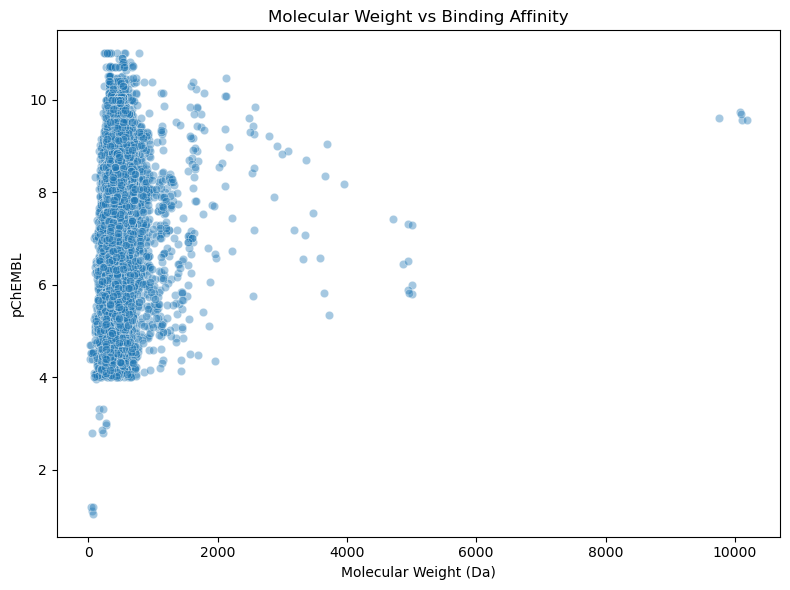

In [27]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=ml_df,
    x="mol_weight",
    y="pchembl_value",
    alpha=0.4
)

plt.xlabel("Molecular Weight (Da)")
plt.ylabel("pChEMBL")
plt.title("Molecular Weight vs Binding Affinity")

plt.tight_layout()
plt.show()

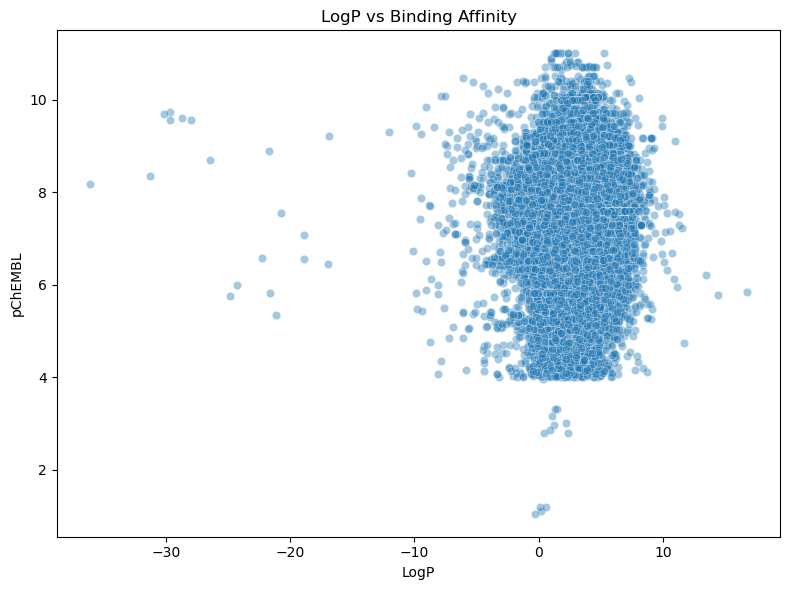

In [28]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=ml_df,
    x="logp",
    y="pchembl_value",
    alpha=0.4
)

plt.xlabel("LogP")
plt.ylabel("pChEMBL")
plt.title("LogP vs Binding Affinity")

plt.tight_layout()
plt.show()

## 13. Molecular Feature Correlation With Binding Affinity

Pearson correlation coefficients are calculated between molecular
descriptors and pChEMBL.

These correlations describe linear associations and should not be
interpreted as evidence of causation.

In [29]:
affinity_corr = (
    ml_df[
        drug_feature_columns + ["pchembl_value"]
    ]
    .corr()["pchembl_value"]
    .sort_values(ascending=False)
)

affinity_corr

pchembl_value      1.000000
ring_count         0.084115
mol_weight         0.079117
fraction_csp3      0.061310
hba                0.060908
rotatable_bonds    0.042780
tpsa               0.040932
hbd               -0.010396
logp              -0.012106
Name: pchembl_value, dtype: float64

## 14. Protein Sequence Characteristics

Protein sequence length is examined across the selected human targets.

Protein size can influence the structural and functional properties
available for molecular recognition.

In [31]:
protein_summary = (
    ml_df[
        [
            "target_chembl_id",
            "pref_name_x",
            "sequence_length"
        ]
    ]
    .drop_duplicates()
)

protein_summary.sort_values(
    "sequence_length",
    ascending=False
)

,target_chembl_id,pref_name_x,sequence_length
1,CHEMBL203,Epidermal growth factor receptor,1210
0,CHEMBL1862,Tyrosine-protein kinase ABL1,1130
22,CHEMBL1801,Plasminogen,810
49,CHEMBL2034,Glucocorticoid receptor,777
168,CHEMBL2000,Plasma kallikrein,638
4,CHEMBL204,Prothrombin,622
333,CHEMBL206,Estrogen receptor,595
2,CHEMBL231,Histamine H1 receptor,487
584,CHEMBL1952,Thymidylate synthase,313
3,CHEMBL205,Carbonic anhydrase 2,260


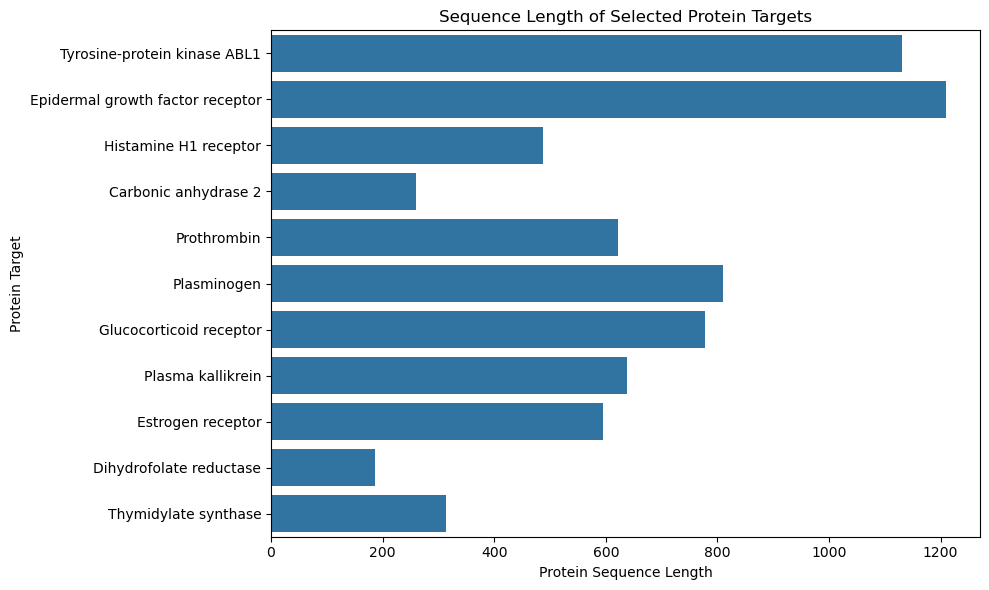

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=protein_summary,
    x="sequence_length",
    y="pref_name_x"
)

plt.xlabel("Protein Sequence Length")
plt.ylabel("Protein Target")
plt.title("Sequence Length of Selected Protein Targets")

plt.tight_layout()
plt.show()

In [34]:
protein_feature_columns = [
    "sequence_length",
    "A_freq", "C_freq", "D_freq", "E_freq",
    "F_freq", "G_freq", "H_freq", "I_freq",
    "K_freq", "L_freq", "M_freq", "N_freq",
    "P_freq", "Q_freq", "R_freq", "S_freq",
    "T_freq", "V_freq", "W_freq", "Y_freq",
    "hydrophobic_fraction",
    "charged_fraction",
    "aromatic_fraction"
]

## 15. Protein Feature Relationships With Binding Affinity

The relationship between sequence-derived protein features and measured
binding affinity is explored using correlation analysis.

Because the dataset contains only 11 unique protein targets, these
correlations should be interpreted cautiously. Many drug–protein pairs
share the same protein-level features.

In [35]:
protein_affinity_corr = (
    ml_df[
        protein_feature_columns + ["pchembl_value"]
    ]
    .corr()["pchembl_value"]
    .sort_values(ascending=False)
)

protein_affinity_corr

pchembl_value           1.000000
S_freq                  0.168836
K_freq                  0.124386
L_freq                  0.101752
Q_freq                  0.087993
H_freq                  0.058075
G_freq                  0.044408
F_freq                  0.042542
D_freq                  0.032181
hydrophobic_fraction    0.009013
P_freq                  0.001730
V_freq                 -0.007189
I_freq                 -0.013179
sequence_length        -0.013538
A_freq                 -0.014442
N_freq                 -0.015683
T_freq                 -0.027162
M_freq                 -0.027332
aromatic_fraction      -0.034104
W_freq                 -0.056954
charged_fraction       -0.078147
E_freq                 -0.111975
C_freq                 -0.123295
Y_freq                 -0.148987
R_freq                 -0.154956
Name: pchembl_value, dtype: float64

## 16. Generate Morgan Molecular Fingerprints

Simple molecular descriptors capture global physicochemical properties
but do not fully represent molecular topology.

Morgan fingerprints provide a structural representation based on the
local chemical environment surrounding atoms.

The fingerprint will complement the interpretable molecular descriptors
and provide the machine-learning model with information about molecular
substructures.

In [41]:
from rdkit.Chem import rdFingerprintGenerator

morgan_generator = rdFingerprintGenerator.GetMorganGenerator(
    radius=2,
    fpSize=256
)

In [42]:
def generate_morgan_fingerprint(mol):
    if mol is None:
        return None
    
    fp = morgan_generator.GetFingerprint(mol)
    
    return list(fp)

In [46]:
drug_features = pd.read_csv(
    "../data/processed/drug_features.csv"
)

drug_features["mol"] = drug_features["canonical_smiles"].apply(
    Chem.MolFromSmiles
)

In [48]:
morgan_matrix = np.array([
    generate_morgan_fingerprint(mol)
    for mol in drug_features["mol"]
])

print("Morgan fingerprint shape:", morgan_matrix.shape)

Morgan fingerprint shape: (18097, 256)


In [49]:
morgan_df = pd.DataFrame(
    morgan_matrix,
    columns=[f"morgan_{i}" for i in range(256)]
)

morgan_df.insert(
    0,
    "molecule_chembl_id",
    drug_features["molecule_chembl_id"].values
)

morgan_df.to_csv(
    "../data/processed/drug_morgan_fingerprints.csv",
    index=False
)

print("Morgan fingerprints saved successfully.")

Morgan fingerprints saved successfully.


## 19. EDA and Feature Engineering Summary

### Dataset
- 18,745 complete drug–protein observations
- 11 human protein targets
- Experimental pChEMBL binding-affinity values

### Drug Representation
- Molecular weight
- LogP
- TPSA
- Hydrogen-bond donors
- Hydrogen-bond acceptors
- Rotatable bonds
- Ring count
- Fraction Csp3
- 256-bit Morgan fingerprints

### Protein Representation
- Protein sequence length
- 20 amino-acid composition features
- Hydrophobic residue fraction
- Charged residue fraction
- Aromatic residue fraction

### Key Findings
Simple molecular descriptors showed relatively weak individual
correlations with binding affinity, suggesting that molecular structure
contains information not captured by basic physicochemical descriptors
alone.

Morgan fingerprints were therefore added to capture molecular
substructure information.

Protein-level correlations were interpreted cautiously because only
11 unique protein targets are represented.

### Next Step
The next notebook will develop and evaluate machine-learning models
using the integrated drug and protein representations.